Image Classification with CNN and Data Augmentation

In [2]:
# Core libraries
import os # work with folders / qovluqlarla işləmək üçün
import zipfile # unzip files / zip faylı açmaq üçün
import numpy as np # numerical operations / ədədi hesablamalar üçün
import matplotlib.pyplot as plt # basic plotting / sadə qrafiklər çəkmək
import seaborn as sns # advanced statistical plots / statistik vizuallaşdırma

# PyTorch tools
import torch # main deep learning library / əsas dərin öyrənmə kitabxanası
import torch.nn as nn # layers and loss functions / layerlər və loss funksiyaları
import torch.optim as optim # optimizers / optimizatorlar
from torch.utils.data import DataLoader # load data in batches / məlumatı batch-lərlə yükləmək
from torchvision import datasets, transforms # ImageFolder and image transformations / şəkil dataseti və çevrilmələr

# Evaluation tools from scikit-learn
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Random seed for reproducibility (ensures same results each run)
RANDOM_STATE = 42  # eyni nəticə üçün sabit təsadüfi başlanğıc
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


plt.rcParams['figure.figsize'] = (10,5) # default figure size / qrafik ölçüsü
plt.rcParams['font.size'] = 12 # font size / şrift ölçüsü

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


Step 1: Dataset Preparation

1.1 Download dataset and extract images

In [12]:
train_dir = os.path.join(extract_dir, "seg_train", "seg_train")
test_dir = os.path.join(extract_dir, "seg_test", "seg_test")

print("Train folder classes:", os.listdir(train_dir))
print("Test folder classes:", os.listdir(test_dir))

# Count images in each class folder
for split_name, split_dir in [("Train", train_dir), ("Test", test_dir)]:
    print(f"\n{split_name} images per class:")
    for class_name in sorted(os.listdir(split_dir)):
        count = len(os.listdir(os.path.join(split_dir, class_name)))
        print(f"  {class_name}: {count}")

Train folder classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Test folder classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Train images per class:
  buildings: 2191
  forest: 2271
  glacier: 2404
  mountain: 2512
  sea: 2274
  street: 2382

Test images per class:
  buildings: 437
  forest: 474
  glacier: 553
  mountain: 525
  sea: 510
  street: 501


1.2 Use ImageFolder (PyTorch)

In [14]:
# ImageFolder reads images from folders, folder name = class label
# (first with basic transform only, augmentation is added in step 2)
basic_transform = transforms.Compose([
    transforms.Resize((150, 150)), # resize to 150x150
    transforms.ToTensor() # convert to tensor and scale pixels to [0, 1]
])

train_data_basic = datasets.ImageFolder(train_dir, transform=basic_transform)
test_data = datasets.ImageFolder(test_dir, transform=basic_transform)

class_names = train_data_basic.classes
print("Classes:", class_names)
print("Class to index:", train_data_basic.class_to_idx)
print("Number of train images:", len(train_data_basic))
print("Number of test images:", len(test_data))

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class to index: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
Number of train images: 14034
Number of test images: 3000


1.3 Apply image transformations (Resize 150x150, ToTensor, Normalize to [0, 1])

In [15]:
# Check one sample: shape and pixel range
image, label = train_data_basic[0]
print("Image shape (channels, height, width):", image.shape)
print("Label:", label, "->", class_names[label])
print("Min pixel value:", image.min().item())
print("Max pixel value:", image.max().item())
# ToTensor divides pixel values by 255, so the values are already in [0, 1]

Image shape (channels, height, width): torch.Size([3, 150, 150])
Label: 0 -> buildings
Min pixel value: 0.0
Max pixel value: 1.0


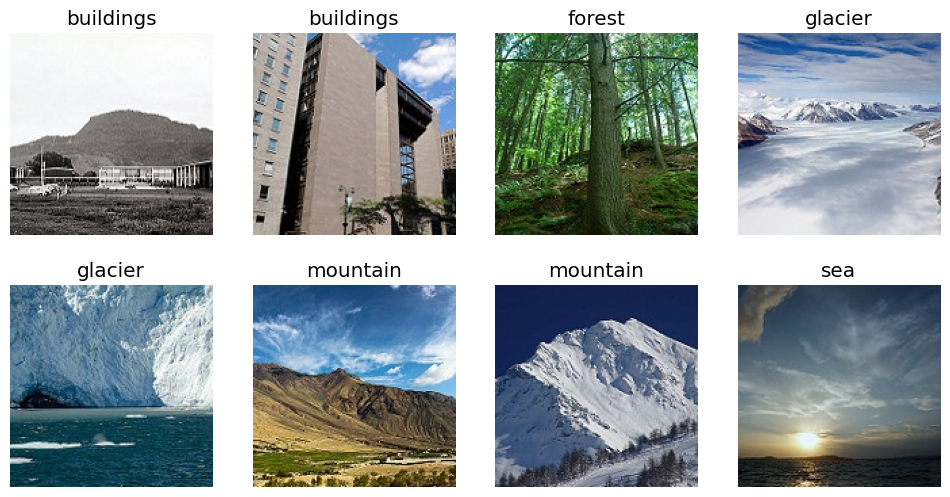

In [16]:
# Show some training images
plt.figure(figsize=(12, 6))
for i in range(8):
    img, lbl = train_data_basic[i * 1500]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img.permute(1, 2, 0)) # (C,H,W) -> (H,W,C) for matplotlib
    plt.title(class_names[lbl])
    plt.axis('off')
plt.show()

Step 2: Data Augmentation (only for training set)

In [17]:
# Augmentation: only for training set, test set stays the same
train_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(p=0.5), # random horizontal flip
    transforms.RandomRotation(15), # random rotation up to 15 degrees
    transforms.RandomResizedCrop(150, scale=(0.8, 1.0)), # random crop and resize back to 150x150
    transforms.ToTensor() # values in [0, 1]
])

train_data = datasets.ImageFolder(train_dir, transform=train_transform)
print("Train images:", len(train_data))
print("Test images:", len(test_data))

Train images: 14034
Test images: 3000


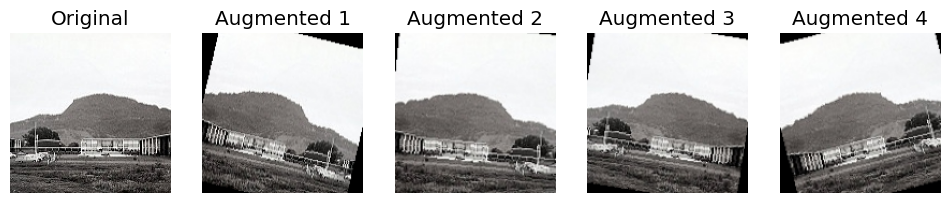

In [18]:
# Show the same image several times with augmentation to see the effect
from PIL import Image
sample_path, sample_label = train_data.samples[0]
sample_img = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(12, 3))
plt.subplot(1, 5, 1)
plt.imshow(sample_img.resize((150, 150)))
plt.title("Original")
plt.axis('off')
for i in range(4):
    plt.subplot(1, 5, i + 2)
    plt.imshow(train_transform(sample_img).permute(1, 2, 0))
    plt.title(f"Augmented {i+1}")
    plt.axis('off')
plt.show()

In [19]:
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("One batch of images:", images.shape)
print("One batch of labels:", labels.shape)

One batch of images: torch.Size([32, 3, 150, 150])
One batch of labels: torch.Size([32])


Step 3: CNN Architecture

In [20]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super(CNN, self).__init__()
        # Convolutional part
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3), # 150x150 -> 148x148
            nn.ReLU(),
            nn.MaxPool2d(2), # 148 -> 74

            nn.Conv2d(32, 64, kernel_size=3), # 74 -> 72
            nn.ReLU(),
            nn.MaxPool2d(2), # 72 -> 36

            nn.Conv2d(64, 128, kernel_size=3), # 36 -> 34
            nn.ReLU(),
            nn.MaxPool2d(2) # 34 -> 17
        )
        # Fully connected part
        self.classifier = nn.Sequential(
            nn.Flatten(), # 128 x 17 x 17 = 36992 values
            nn.Linear(128 * 17 * 17, 128),
            nn.ReLU(),
            nn.Dropout(0.5), # randomly turn off 50% of neurons to reduce overfitting
            nn.Linear(128, num_classes) # output layer
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x # raw scores (logits)

# Softmax is not written in the model because CrossEntropyLoss already applies softmax inside
model = CNN(num_classes=len(class_names)).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=36992, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)
Total parameters: 4829126


Step 4: Training Setup

In [21]:
# Loss function, optimizer and number of epochs
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
num_epochs = 25

In [22]:
# Function to evaluate the model on a dataloader (returns loss, accuracy)
def evaluate(model, loader):
    model.eval() # evaluation mode (dropout is off)
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad(): # no gradients needed for evaluation
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

In [23]:
# Training loop
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(num_epochs):
    model.train() # training mode (dropout is on)
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad() # clear old gradients
        outputs = model(images) # forward pass
        loss = criterion(outputs, labels) # calculate loss
        loss.backward() # backward pass
        optimizer.step() # update weights

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    test_loss, test_acc = evaluate(model, test_loader)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}")

Epoch [1/25] Train Loss: 1.1478, Train Acc: 0.5502 | Test Loss: 0.8528, Test Acc: 0.6543
Epoch [2/25] Train Loss: 0.8972, Train Acc: 0.6597 | Test Loss: 0.6781, Test Acc: 0.7473
Epoch [3/25] Train Loss: 0.7717, Train Acc: 0.7247 | Test Loss: 0.5991, Test Acc: 0.7837
Epoch [4/25] Train Loss: 0.7173, Train Acc: 0.7453 | Test Loss: 0.5963, Test Acc: 0.8027
Epoch [5/25] Train Loss: 0.6450, Train Acc: 0.7711 | Test Loss: 0.5119, Test Acc: 0.8167
Epoch [6/25] Train Loss: 0.6136, Train Acc: 0.7816 | Test Loss: 0.4870, Test Acc: 0.8263
Epoch [7/25] Train Loss: 0.5868, Train Acc: 0.7904 | Test Loss: 0.4582, Test Acc: 0.8337
Epoch [8/25] Train Loss: 0.5560, Train Acc: 0.8053 | Test Loss: 0.4540, Test Acc: 0.8367
Epoch [9/25] Train Loss: 0.5407, Train Acc: 0.8126 | Test Loss: 0.4222, Test Acc: 0.8513
Epoch [10/25] Train Loss: 0.5206, Train Acc: 0.8169 | Test Loss: 0.4523, Test Acc: 0.8477
Epoch [11/25] Train Loss: 0.5006, Train Acc: 0.8195 | Test Loss: 0.4435, Test Acc: 0.8440
Epoch [12/25] Train

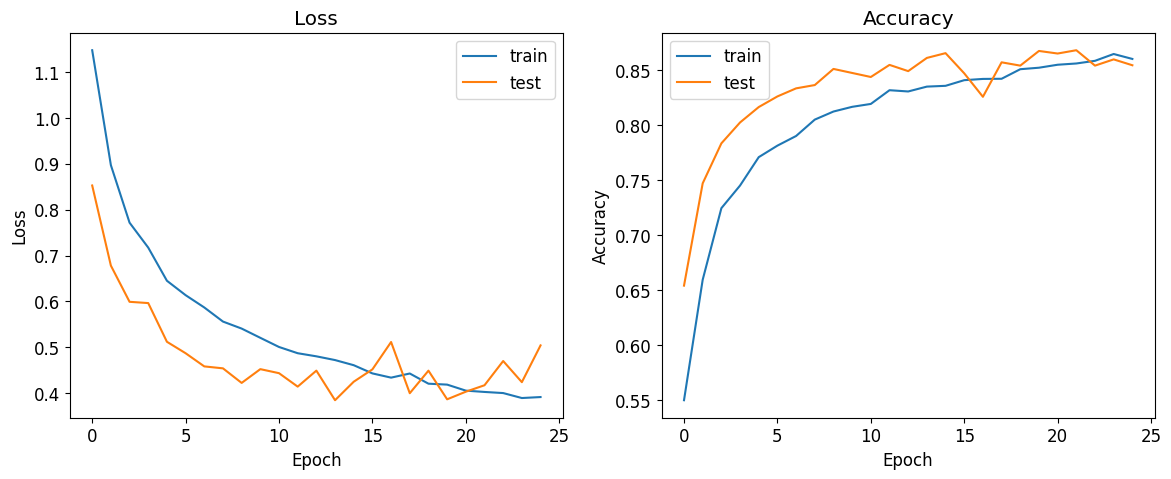

In [24]:
# Plot loss and accuracy curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='train')
plt.plot(history['test_loss'], label='test')
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='train')
plt.plot(history['test_acc'], label='test')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

Step 5: Evaluation

5.1 Accuracy on test set

In [25]:
# Get predictions for the whole test set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Test accuracy: {test_accuracy:.4f}")

print("\nClassification report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

Test accuracy: 0.8547

Classification report:
              precision    recall  f1-score   support

   buildings       0.85      0.85      0.85       437
      forest       0.90      0.97      0.93       474
     glacier       0.91      0.73      0.81       553
    mountain       0.79      0.83      0.81       525
         sea       0.81      0.90      0.85       510
      street       0.89      0.86      0.88       501

    accuracy                           0.85      3000
   macro avg       0.86      0.86      0.86      3000
weighted avg       0.86      0.85      0.85      3000



5.2 Confusion matrix

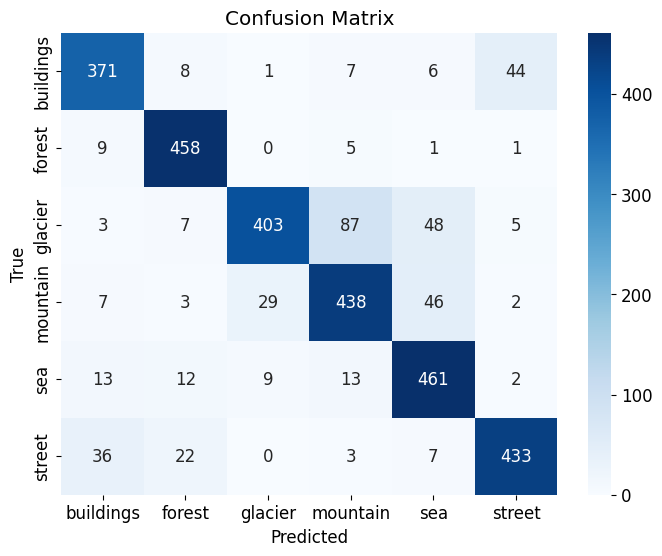

In [26]:
# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

5.3 Visualize 10 correctly classified and 10 misclassified samples

Correct: 2564 | Misclassified: 436


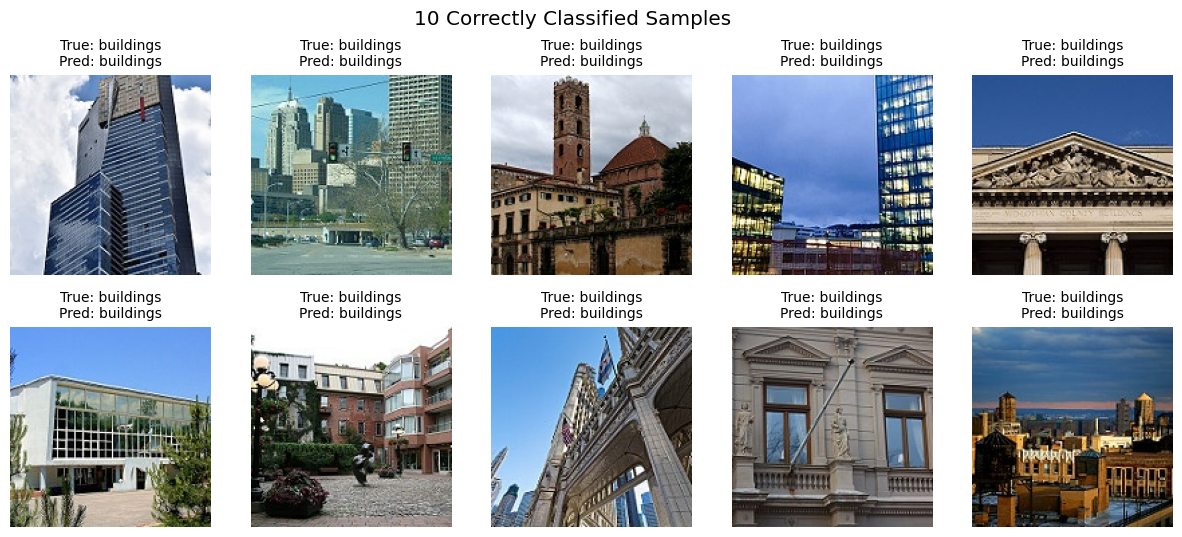

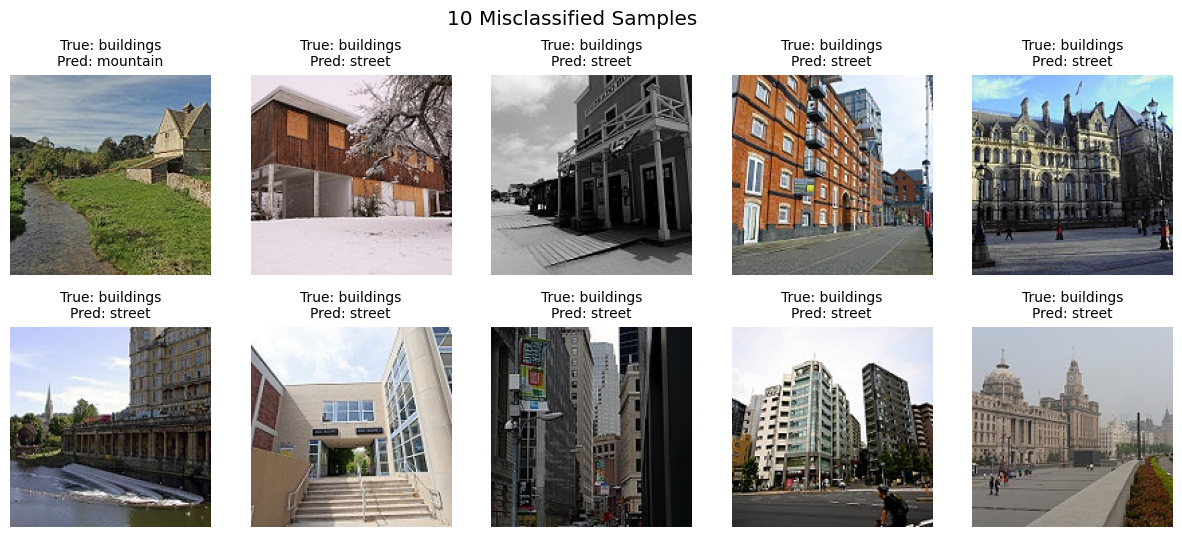

In [27]:
# Indexes of correct and wrong predictions
correct_idx = np.where(all_preds == all_labels)[0]
wrong_idx = np.where(all_preds != all_labels)[0]
print("Correct:", len(correct_idx), "| Misclassified:", len(wrong_idx))

# Function to show 10 images in a 2x5 grid
def show_samples(indexes, title):
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(indexes[:10]):
        img, _ = test_data[idx]
        plt.subplot(2, 5, i + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.title(f"True: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}", fontsize=10)
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# First 10 of each group
show_samples(correct_idx, "10 Correctly Classified Samples")
show_samples(wrong_idx, "10 Misclassified Samples")